# Bài 4: Transfer learning ResNet-50 trên VinaFood21

So sánh feature extraction và fine-tuning với `microsoft/resnet-50`.

In [ ]:
EXERCISE = 4

from pathlib import Path
import os
import sys
import json

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

CODE_DIR = Path(f"*path chứa source code*")
DATA_ROOT = Path("*path chứa dữ liệu VinaFood21*")
OUTPUT_DIR = Path(f"*path chứa output*")

if not (CODE_DIR / "train.py").is_file():
    raise FileNotFoundError(f"Không tìm thấy train.py tại {CODE_DIR}")
if not (DATA_ROOT / "train").is_dir() or not (DATA_ROOT / "test").is_dir():
    raise FileNotFoundError(
        f"DATA_ROOT phải chứa trực tiếp train/ và test/: {DATA_ROOT}"
    )

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))
os.chdir(CODE_DIR)

print("Code:", CODE_DIR)
print("Data:", DATA_ROOT)
print("Output:", OUTPUT_DIR)

Code: /kaggle/input/datasets/vantien113/code-lab2/4/4
Data: /kaggle/input/datasets/maivthysao/lab2-bai3/VinaFood21/VinaFood21
Output: /kaggle/working/lab2_bai4_outputs


## 1. Kiểm tra môi trường và cấu hình

In [ ]:
RUN_TRAIN = True
RUN_EVALUATION = True

SEED = 42
BATCH_SIZE = 32
NUM_WORKERS = 2
EPOCHS = 20
IMAGE_SIZE = 224

import torch
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
print("Epochs:", EPOCHS, "| Batch size:", BATCH_SIZE, "| Image size:", IMAGE_SIZE)
if DEVICE.type != "cuda":
    print("Chưa bật GPU")


try:
    import transformers
    print("transformers:", transformers.__version__)
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "transformers"])
    import transformers
    print("Đã cài transformers:", transformers.__version__)
print("Bài 4 cần bật Internet để tải microsoft/resnet-50 lần đầu.")

PyTorch: 2.11.0+cu128
Device: cuda
Epochs: 20 | Batch size: 32 | Image size: 224
transformers: 5.16.1
Bài 4 cần bật Internet để tải microsoft/resnet-50 lần đầu.


In [ ]:
def run_module_main(module, arguments):
    """Gọi main() của module."""
    old_argv = sys.argv[:]
    sys.argv = [f"{module.__name__}.py", *map(str, arguments)]
    try:
        module.main()
    finally:
        sys.argv = old_argv

## 2. Huấn luyện

In [ ]:
if RUN_TRAIN:
    import train as train_module
    train_arguments = ['--mode', 'both', '--epochs', '20', '--img_size', '224', '--feature_lr', '0.001', '--finetune_lr', '0.0001', '--data_root', 'VinaFood21', '--batch_size', '32', '--num_workers', '2', '--seed', '42', '--out_dir', 'lab2_bai4_outputs']
    runtime_values = {
        "--data_root": DATA_ROOT,
        "--out_dir": OUTPUT_DIR,
        "--batch_size": BATCH_SIZE,
        "--num_workers": NUM_WORKERS,
        "--seed": SEED,
        "--epochs": EPOCHS,
        "--img_size": IMAGE_SIZE,
    }
    for flag, value in runtime_values.items():
        train_arguments[train_arguments.index(flag) + 1] = str(value)
    run_module_main(train_module, train_arguments)
else:
    print("Bỏ qua train theo cấu hình RUN_TRAIN=False")

config.json:   0%|          | 0.00/69.6k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]


Bai4_ResNet50_feature | device=cuda | data=/kaggle/input/datasets/maivthysao/lab2-bai3/VinaFood21/VinaFood21 | train=8537 | val=1507 | params=23,551,061 | trainable=43,029


...

epoch 01 | train 2.1342/0.4554 | val 1.6525/0.5939 | macro-F1 0.5961 | 457.7s -> saved Bai4_ResNet50_feature_best.pt
epoch 02 | train 1.4000/0.6505 | val 1.3028/0.6576 | macro-F1 0.6609 | 118.5s -> saved Bai4_ResNet50_feature_best.pt
epoch 03 | train 1.1497/0.7019 | val 1.1389/0.6841 | macro-F1 0.6882 | 117.7s -> saved Bai4_ResNet50_feature_best.pt
epoch 04 | train 1.0078/0.7299 | val 1.0496/0.7021 | macro-F1 0.7095 | 117.6s -> saved Bai4_ResNet50_feature_best.pt
epoch 05 | train 0.9190/0.7500 | val 0.9905/0.7100 | macro-F1 0.7126 | 117.4s -> saved Bai4_ResNet50_feature_best.pt
epoch 06 | train 0.8527/0.7617 | val 0.9439/0.7240 | macro-F1 0.7250 | 117.1s -> saved Bai4_ResNet50_feature_best.pt
epoch 07 | train 0.7998/0.7752 | val 0.9046/0.7259 | macro-F1 0.7329 | 114.0s -> saved Bai4_ResNet50_feature_best.pt
epoch 08 | train 0.7559/0.7867 | val 0.8757/0.7313 | macro-F1 0.7380 | 112.9s -> saved Bai4_ResNet50_feature_best.pt
epoch 09 | train 0.7201/0.8018 | val 0.8622/0.7359 | macro-F1 0.

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]


Bai4_ResNet50_finetune | device=cuda | data=/kaggle/input/datasets/maivthysao/lab2-bai3/VinaFood21/VinaFood21 | train=8537 | val=1507 | params=23,551,061 | trainable=23,551,061


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 01 | train 2.7668/0.1809 | val 2.3349/0.4101 | macro-F1 0.3116 | 127.2s -> saved Bai4_ResNet50_finetune_best.pt
epoch 02 | train 1.6840/0.5556 | val 1.1674/0.6709 | macro-F1 0.6563 | 128.0s -> saved Bai4_ResNet50_finetune_best.pt
epoch 03 | train 0.9650/0.7197 | val 0.8321/0.7445 | macro-F1 0.7281 | 126.7s -> saved Bai4_ResNet50_finetune_best.pt
epoch 04 | train 0.6914/0.7900 | val 0.6535/0.7956 | macro-F1 0.7805 | 126.8s -> saved Bai4_ResNet50_finetune_best.pt
epoch 05 | train 0.5380/0.8380 | val 0.5799/0.8122 | macro-F1 0.8025 | 127.5s -> saved Bai4_ResNet50_finetune_best.pt
epoch 06 | train 0.4373/0.8658 | val 0.5454/0.8261 | macro-F1 0.8138 | 126.3s -> saved Bai4_ResNet50_finetune_best.pt
epoch 07 | train 0.3750/0.8849 | val 0.5043/0.8407 | macro-F1 0.8321 | 127.0s -> saved Bai4_ResNet50_finetune_best.pt
epoch 08 | train 0.3332/0.8973 | val 0.4902/0.8534 | macro-F1 0.8467 | 128.0s -> saved Bai4_ResNet50_finetune_best.pt
epoch 09 | train 0.2665/0.9178 | val 0.4646/0.8640 | mac

## 3. Đánh giá best checkpoint trên tập test

In [5]:
if RUN_EVALUATION:
    import evaluate as evaluate_module
    for mode in ("feature", "finetune"):
        checkpoint = OUTPUT_DIR / f"Bai4_ResNet50_{mode}_best.pt"
        if not checkpoint.is_file():
            raise FileNotFoundError(checkpoint)
        run_module_main(evaluate_module, [
            "--data_root", str(DATA_ROOT), "--mode", mode,
            "--ckpt", str(checkpoint), "--batch_size", str(BATCH_SIZE),
            "--num_workers", str(NUM_WORKERS),
        ])
else:
    print("Bỏ qua evaluate theo cấu hình RUN_EVALUATION=False")

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Bai4_ResNet50_feature | data=/kaggle/input/datasets/maivthysao/lab2-bai3/VinaFood21/VinaFood21 | best epoch=20 | accuracy=0.7462 | macro-F1=0.7539
Bảng tổng hợp các kết quả hiện có: /kaggle/working/lab2_bai4_outputs/Lab2_model_comparison.csv


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Bai4_ResNet50_finetune | data=/kaggle/input/datasets/maivthysao/lab2-bai3/VinaFood21/VinaFood21 | best epoch=19 | accuracy=0.8608 | macro-F1=0.8621
Bảng tổng hợp các kết quả hiện có: /kaggle/working/lab2_bai4_outputs/Lab2_model_comparison.csv


## 4. Toàn bộ lịch sử train theo epoch

In [6]:
history_files = sorted(OUTPUT_DIR.glob("*_history.csv"))
if not history_files:
    raise FileNotFoundError("Không có history CSV; cell train chưa chạy thành công.")

histories = {}
for path in history_files:
    name = path.stem.removesuffix("_history")
    frame = pd.read_csv(path)
    histories[name] = frame
    display(Markdown(f"### Lịch sử epoch — `{name}`"))
    display(frame.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name, frame in histories.items():
    axes[0].plot(frame["epoch"], frame["train_loss"], marker="o", label=f"{name} train")
    axes[0].plot(frame["epoch"], frame["val_loss"], marker="o", linestyle="--",
                 label=f"{name} validation")
    axes[1].plot(frame["epoch"], frame["val_f1_macro"], marker="o", label=name)

axes[0].set(title="Train và validation loss", xlabel="Epoch", ylabel="Cross-entropy loss")
axes[1].set(title="Validation macro-F1", xlabel="Epoch", ylabel="Macro-F1")
for axis in axes:
    axis.grid(alpha=.25)
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Lịch sử epoch — `Bai4_ResNet50_feature`

,epoch,train_loss,train_accuracy,val_loss,val_accuracy,val_f1_macro,seconds
0,1,2.1342,0.4554,1.6525,0.5939,0.5961,457.7130
1,2,1.4000,0.6505,1.3028,0.6576,0.6609,118.4772
2,3,1.1497,0.7019,1.1389,0.6841,0.6882,117.6880
3,4,1.0078,0.7299,1.0496,0.7021,0.7095,117.6497
4,5,0.9190,0.7500,0.9905,0.7100,0.7126,117.3699
5,6,0.8527,0.7617,0.9439,0.7240,0.7250,117.1326
6,7,0.7998,0.7752,0.9046,0.7259,0.7329,113.9692
7,8,0.7559,0.7867,0.8757,0.7313,0.7380,112.8528
8,9,0.7201,0.8018,0.8622,0.7359,0.7422,114.0340
9,10,0.6825,0.8085,0.8214,0.7465,0.7536,114.2623


### Lịch sử epoch — `Bai4_ResNet50_finetune`

,epoch,train_loss,train_accuracy,val_loss,val_accuracy,val_f1_macro,seconds
0,1,2.7668,0.1809,2.3349,0.4101,0.3116,127.1962
1,2,1.6840,0.5556,1.1674,0.6709,0.6563,127.9774
2,3,0.9650,0.7197,0.8321,0.7445,0.7281,126.7484
3,4,0.6914,0.7900,0.6535,0.7956,0.7805,126.7900
4,5,0.5380,0.8380,0.5799,0.8122,0.8025,127.5239
5,6,0.4373,0.8658,0.5454,0.8261,0.8138,126.2622
6,7,0.3750,0.8849,0.5043,0.8407,0.8321,127.0120
7,8,0.3332,0.8973,0.4902,0.8534,0.8467,128.0318
8,9,0.2665,0.9178,0.4646,0.8640,0.8567,125.3388
9,10,0.2553,0.9228,0.4573,0.8620,0.8555,127.2047


## 5. Hình train/validation loss

### Hình loss đã lưu — `Bai4_ResNet50_feature_loss.png`

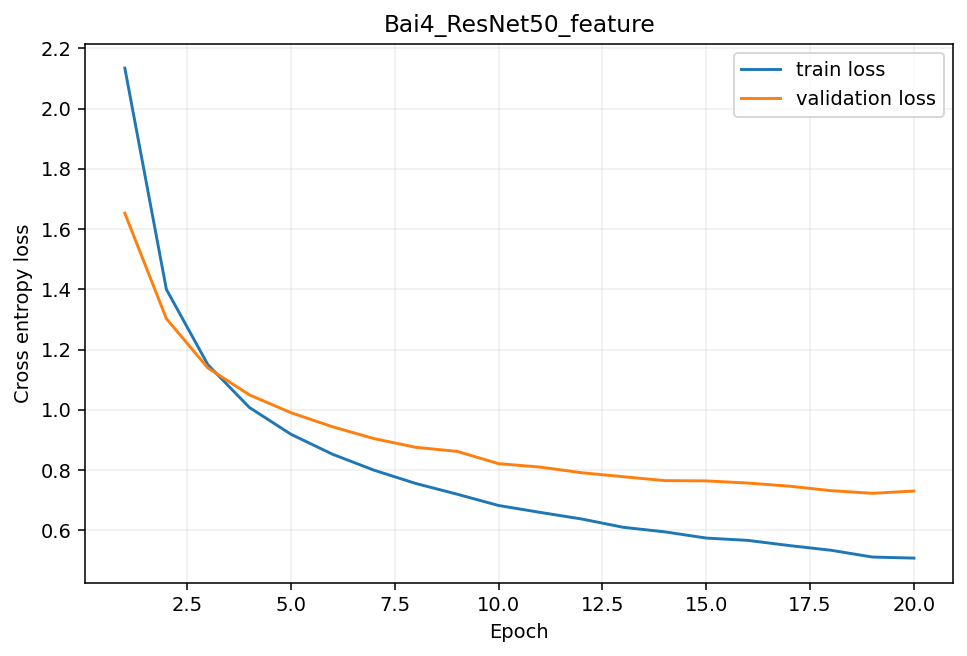

### Hình loss đã lưu — `Bai4_ResNet50_finetune_loss.png`

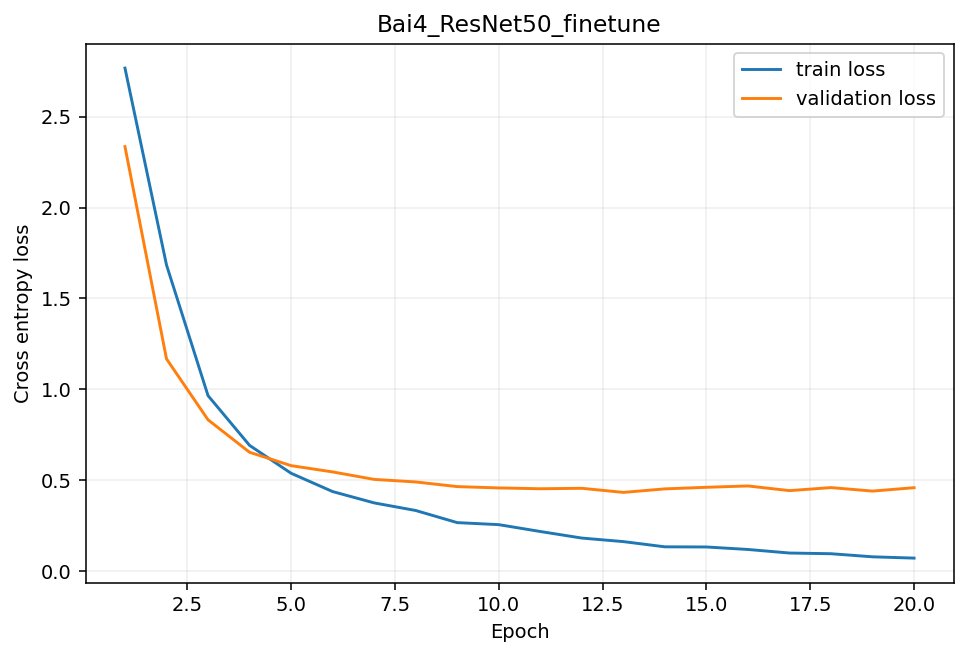

In [7]:
loss_files = sorted(OUTPUT_DIR.glob("*_loss.png"))
for path in loss_files:
    display(Markdown(f"### Hình loss đã lưu — `{path.name}`"))
    display(Image(filename=str(path)))

## 6. Kết quả đánh giá trên test

In [8]:
test_files = sorted(OUTPUT_DIR.glob("*_test.json"))
if not test_files:
    raise FileNotFoundError("Không có test JSON; cell evaluate chưa chạy thành công.")

summaries = []
for path in test_files:
    with path.open(encoding="utf-8") as stream:
        payload = json.load(stream)
    row = payload["summary"].copy()
    row["result_file"] = path.name
    summaries.append(row)

summary_frame = pd.DataFrame(summaries)
preferred = [
    "model", "best_val_epoch", "best_val_f1", "test_loss",
    "accuracy", "precision_macro", "recall_macro", "f1_macro",
    "params", "trainable_params", "seconds_per_epoch", "result_file",
]
shown = [column for column in preferred if column in summary_frame.columns]
display(summary_frame[shown].round(4))

winner = summary_frame.loc[summary_frame["f1_macro"].astype(float).idxmax()]
display(Markdown(
    f"**Mô hình tốt nhất trên test:** `{winner['model']}` — "
    f"accuracy = **{float(winner['accuracy']):.4f}**, "
    f"precision-macro = **{float(winner['precision_macro']):.4f}**, "
    f"recall-macro = **{float(winner['recall_macro']):.4f}**, "
    f"macro-F1 = **{float(winner['f1_macro']):.4f}**."
))

,model,best_val_epoch,best_val_f1,test_loss,accuracy,precision_macro,recall_macro,f1_macro,params,trainable_params,result_file
0,Bai4_ResNet50_feature,20,0.7797,0.8022,0.7462,0.7601,0.7571,0.7539,23551061,43029,Bai4_ResNet50_feature_test.json
1,Bai4_ResNet50_finetune,19,0.8805,0.5099,0.8608,0.8635,0.8640,0.8621,23551061,23551061,Bai4_ResNet50_finetune_test.json


**Mô hình tốt nhất trên test:** `Bai4_ResNet50_finetune` — accuracy = **0.8608**, precision-macro = **0.8635**, recall-macro = **0.8640**, macro-F1 = **0.8621**.

## 7. Kết quả từng lớp

In [9]:
per_class_files = sorted(OUTPUT_DIR.glob("*_per_class.csv"))
for path in per_class_files:
    frame = pd.read_csv(path).sort_values("f1", ascending=False)
    display(Markdown(f"### Precision/Recall/F1 từng lớp — `{path.stem.removesuffix('_per_class')}`"))
    display(frame.round(4))

### Precision/Recall/F1 từng lớp — `Bai4_ResNet50_feature`

,class,precision,recall,f1,support
7,bap-nuong,0.9856,0.9580,0.9716,143
13,canh-khoai-mo,0.9053,0.8687,0.8866,198
19,tau-hu,0.8421,0.8670,0.8544,203
2,banh-mi-chao,0.8078,0.8581,0.8322,289
5,banh-u,0.7817,0.8750,0.8257,176
16,ha-cao,0.8359,0.8062,0.8208,480
12,canh-kho-qua,0.7993,0.8379,0.8182,290
9,bo-la-lot,0.7713,0.8690,0.8172,458
3,banh-tet,0.9522,0.7115,0.8145,364
4,banh-trang-tron,0.8297,0.7411,0.7829,309


### Precision/Recall/F1 từng lớp — `Bai4_ResNet50_finetune`

,class,precision,recall,f1,support
7,bap-nuong,0.9722,0.9790,0.9756,143
12,canh-kho-qua,0.9479,0.9414,0.9446,290
13,canh-khoai-mo,0.9482,0.9242,0.9361,198
9,bo-la-lot,0.9324,0.9039,0.9180,458
2,banh-mi-chao,0.9193,0.9066,0.9129,289
19,tau-hu,0.8947,0.9212,0.9078,203
20,thit-kho-trung,0.8567,0.9385,0.8957,325
0,banh-can,0.8476,0.9461,0.8941,241
16,ha-cao,0.9046,0.8688,0.8863,480
3,banh-tet,0.9864,0.7967,0.8815,364


## 8. Confusion matrix

### Confusion matrix — `Bai4_ResNet50_feature`

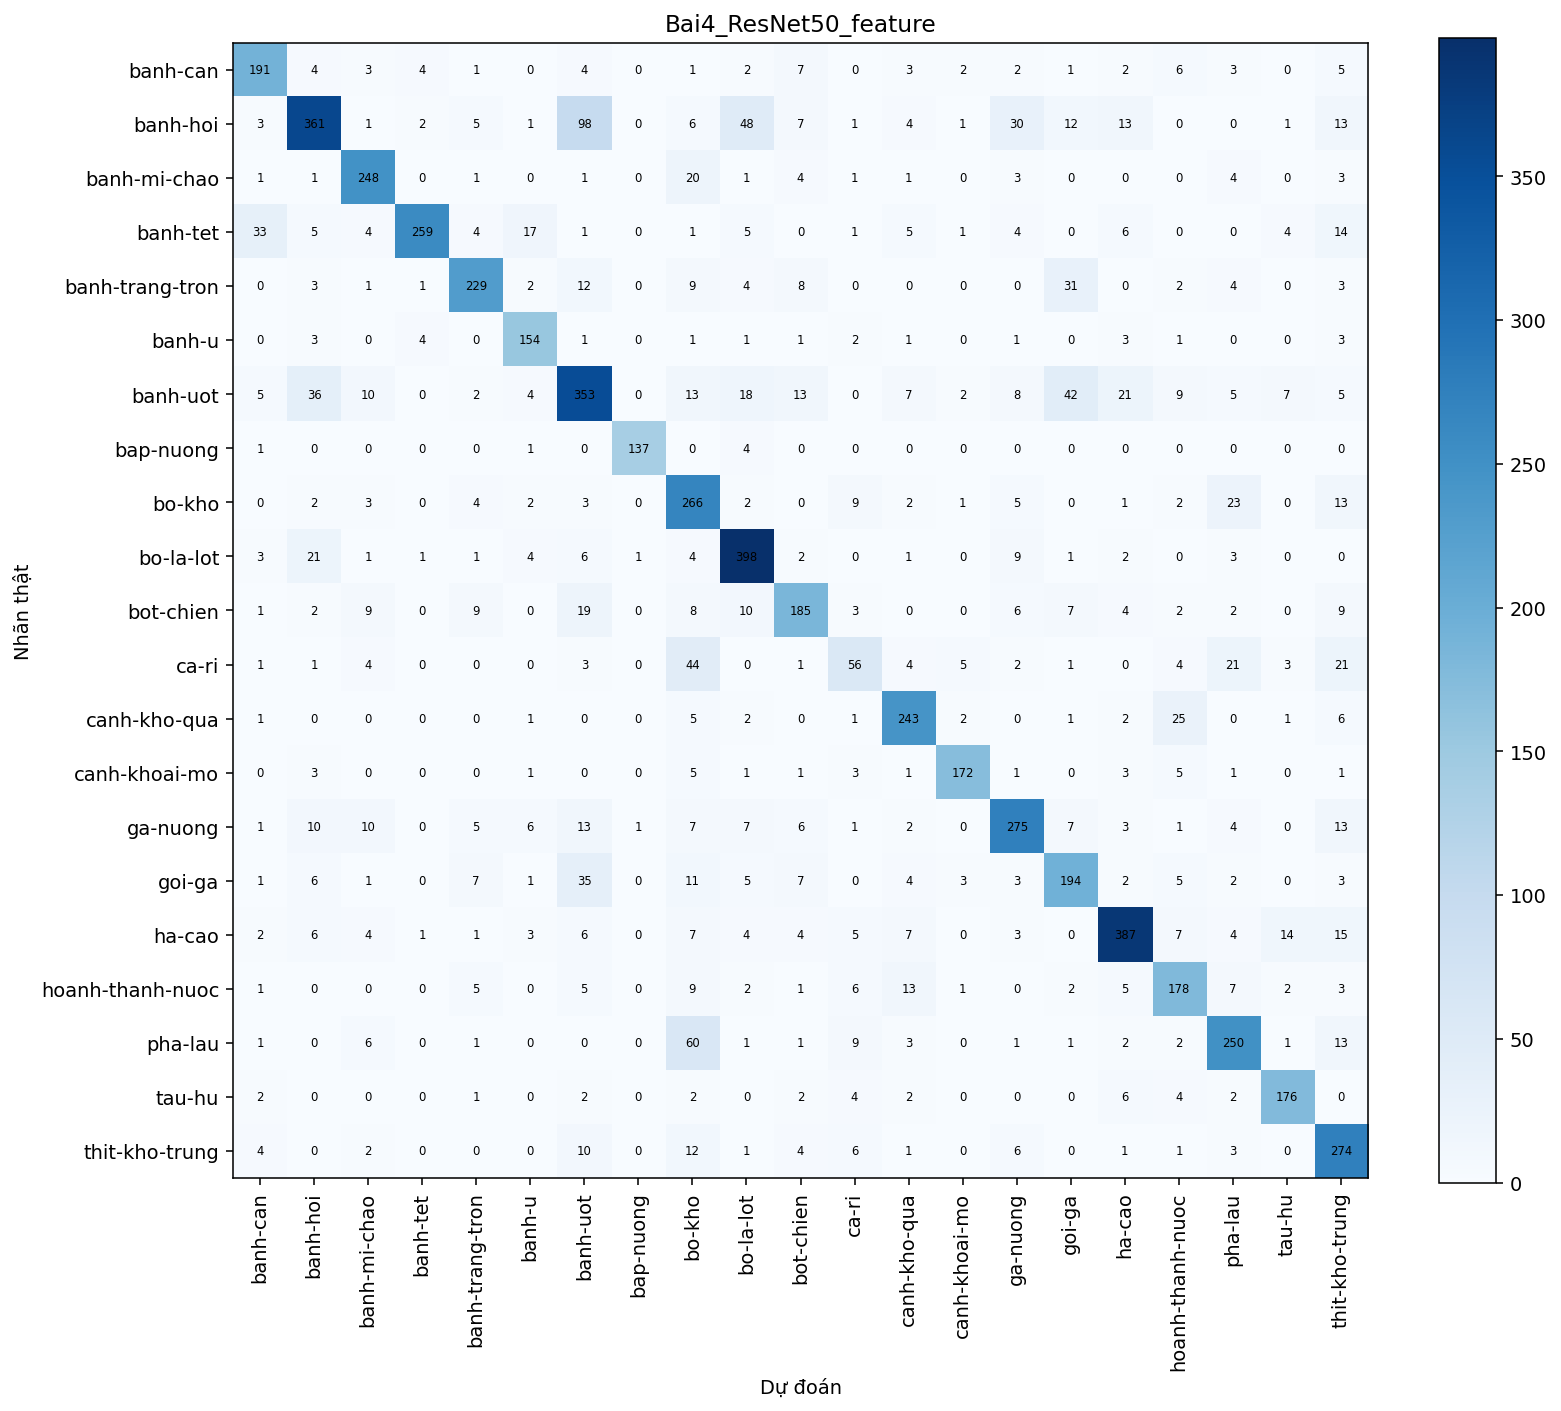

### Confusion matrix — `Bai4_ResNet50_finetune`

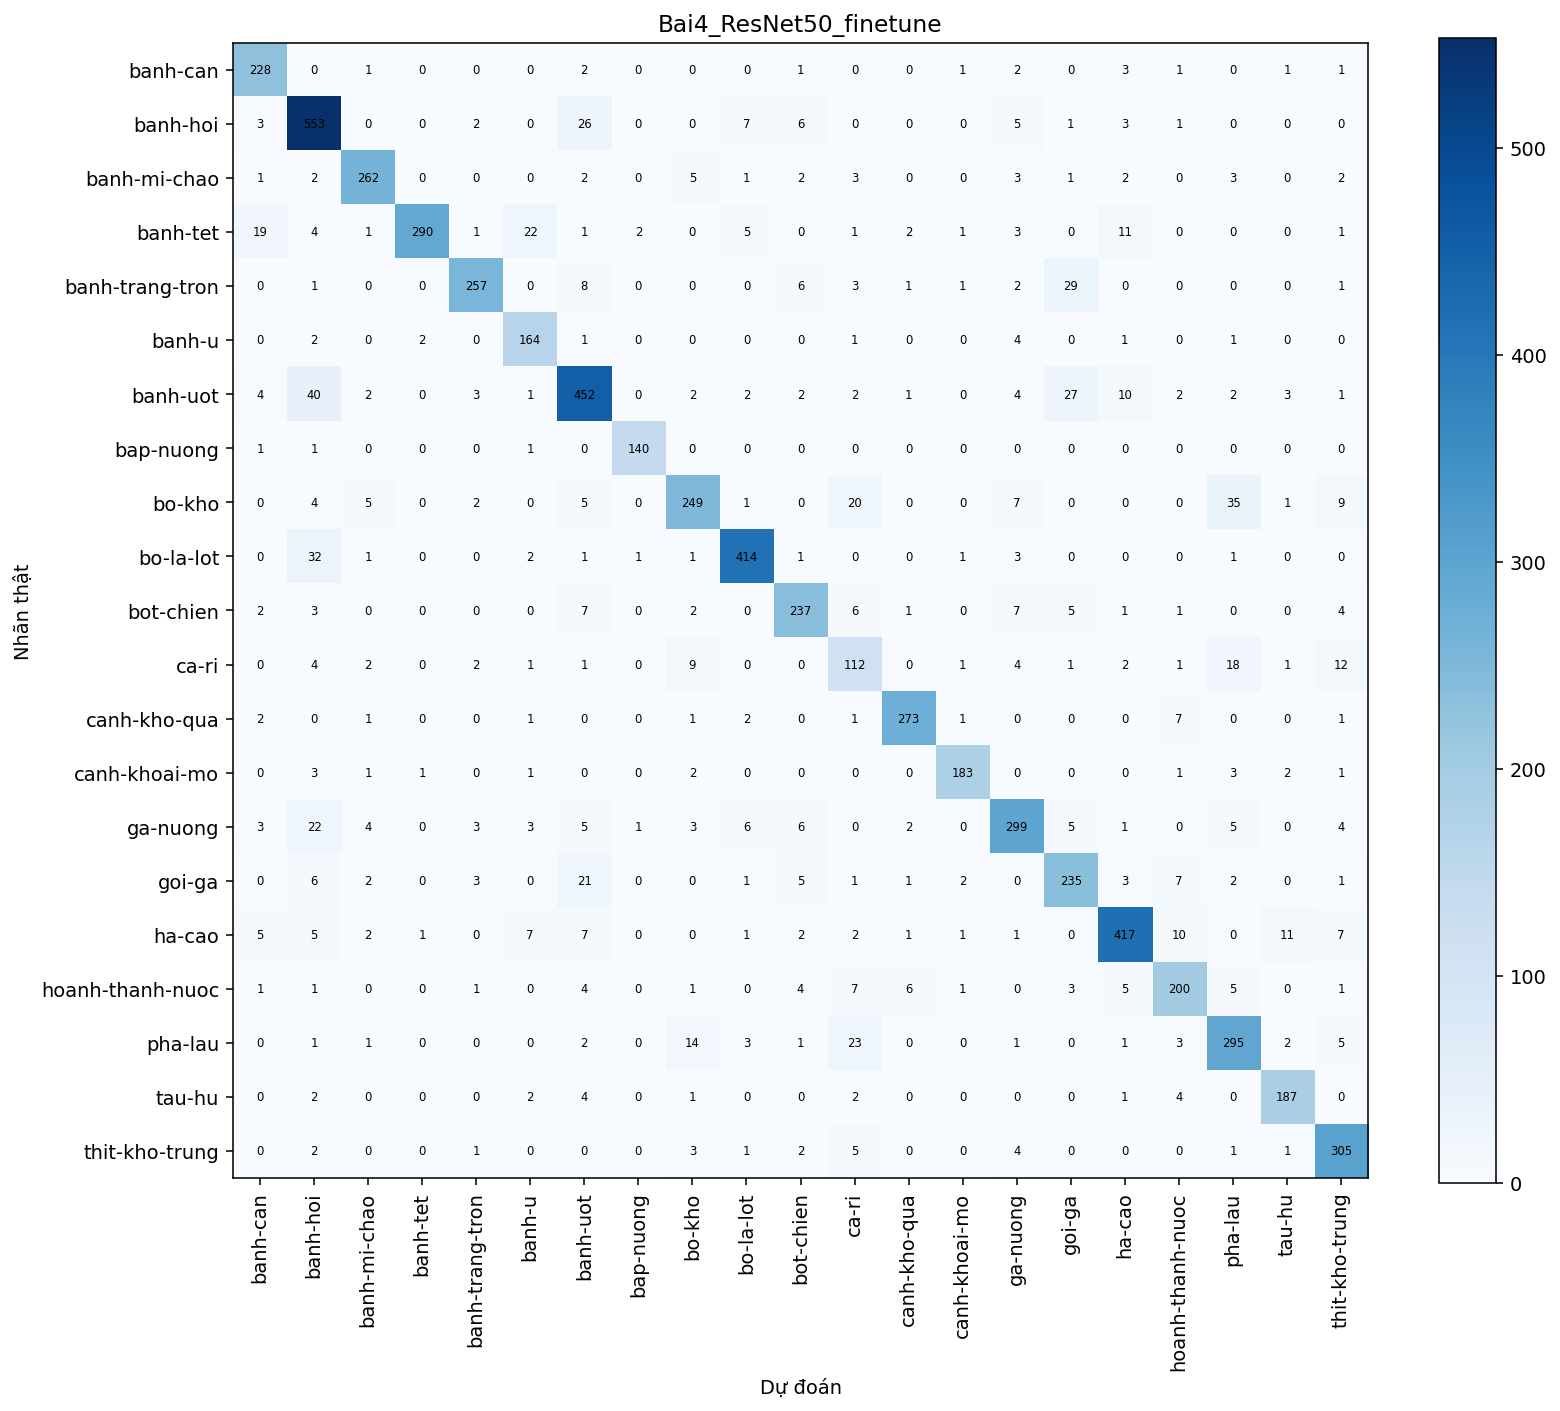

In [10]:
matrix_files = sorted(OUTPUT_DIR.glob("*_confusion_matrix.png"))
for path in matrix_files:
    display(Markdown(f"### Confusion matrix — `{path.stem.removesuffix('_confusion_matrix')}`"))
    display(Image(filename=str(path)))

## 9. Danh sách artifact

In [11]:
rows = [
    {"file": path.name, "size_MB": round(path.stat().st_size / 1024**2, 3)}
    for path in sorted(OUTPUT_DIR.glob("*")) if path.is_file()
]
display(pd.DataFrame(rows))
print("Tất cả artifact được lưu tại:", OUTPUT_DIR)

,file,size_MB
0,Bai4_ResNet50_feature_best.pt,90.153
1,Bai4_ResNet50_feature_confusion_matrix.png,0.155
2,Bai4_ResNet50_feature_history.csv,0.002
3,Bai4_ResNet50_feature_loss.png,0.051
4,Bai4_ResNet50_feature_per_class.csv,0.001
5,Bai4_ResNet50_feature_test.json,0.008
6,Bai4_ResNet50_finetune_best.pt,90.153
7,Bai4_ResNet50_finetune_confusion_matrix.png,0.145
8,Bai4_ResNet50_finetune_history.csv,0.002
9,Bai4_ResNet50_finetune_loss.png,0.047


Tất cả artifact được lưu tại: /kaggle/working/lab2_bai4_outputs


## Kết luận

- Checkpoint được lựa chọn bằng **macro-F1 trên validation**, không dùng test để chọn epoch.
- Các chỉ số test gồm accuracy, precision-macro, recall-macro và macro-F1.